# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [3]:
# Paso 0: Importar librerías necesarias
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [4]:
# Paso 1: Descargar los datos de los 3 activos elegidos
tickers = ['BAC', 'ADBE', 'COP']
start_date = '2024-01-01'
end_date = '2026-01-01'

# Descarga de datos desde Yahoo Finance
datos_brutos = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)

# Mostrar las primeras 5 filas del DataFrame resultante
print("Primeras 5 filas del DataFrame resultante:")
datos_brutos.head()

[*********************100%***********************]  3 of 3 completed

Primeras 5 filas del DataFrame resultante:


Price        Adj Close                              Close             \
Ticker            ADBE        BAC         COP        ADBE        BAC   
Date                                                                   
2024-01-02  580.070007  31.800459  108.177185  580.070007  33.900002   
2024-01-03  571.789978  31.453369  110.329872  571.789978  33.529999   
2024-01-04  567.049988  31.706652  107.156052  567.049988  33.799999   
2024-01-05  564.599976  32.297638  107.202042  564.599976  34.430000   
2024-01-08  580.549988  32.044357  105.334534  580.549988  34.160000   

Price                         High                                Low  \
Ticker             COP        ADBE        BAC         COP        ADBE   
Date                                                                    
2024-01-02  117.589996  590.440002  34.070000  118.800003  576.760010   
2024-01-03  119.930000  577.299988  33.770000  120.180000  570.190002   
2024-01-04  116.480003  572.909973  34.310001  121.239998  566.659973   
2024-01-05  116.529999  569.520020  34.689999  117.769997  563.340027   
2024-01-08  114.500000  581.510010  34.299999  115.050003  567.869995   

Price                                    Open                          Volume  \
Ticker            BAC         COP        ADBE        BAC         COP     ADBE   
Date                                                                            
2024-01-02  33.270000  116.849998  589.510010  33.389999  117.169998  2840200   
2024-01-03  33.240002  117.410004  574.580017  33.650002  117.949997  2478000   
2024-01-04  33.540001  116.269997  570.989990  33.570000  120.610001  2092100   
2024-01-05  33.709999  116.000000  563.500000  33.799999  117.500000  1923200   
2024-01-08  33.639999  112.480003  567.869995  34.299999  114.959999  2830000   

Price                          
Ticker           BAC      COP  
Date                           
2024-01-02  36668600  4688400  
2024-01-03  45988700  4881900  
2024-01-04  39834600  5891500  
2024-01-05  49242400  3984600  
2024-01-08  40253900  6769600

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

**1. Extraer los precios de Cierre**

In [7]:
# 1. Extraer los precios de cierre (Close)
if isinstance(datos_brutos.columns, pd.MultiIndex):
    precios = datos_brutos['Close']
else:
    precios = datos_brutos[['BAC', 'ADBE', 'COP']]

# Limpiar posibles valores nulos
precios = precios.dropna()

print("Precios de cierre extraídos correctamente. Primeras filas:")
display(precios.head())

Precios de cierre extraídos correctamente. Primeras filas:


Ticker,ADBE,BAC,COP
Date,,,
2024-01-02,580.070007,33.900002,117.589996
2024-01-03,571.789978,33.529999,119.930000
2024-01-04,567.049988,33.799999,116.480003
2024-01-05,564.599976,34.430000,116.529999
2024-01-08,580.549988,34.160000,114.500000


**2. Grafica Evolucion Temporal de los Precios Originales Activos.**

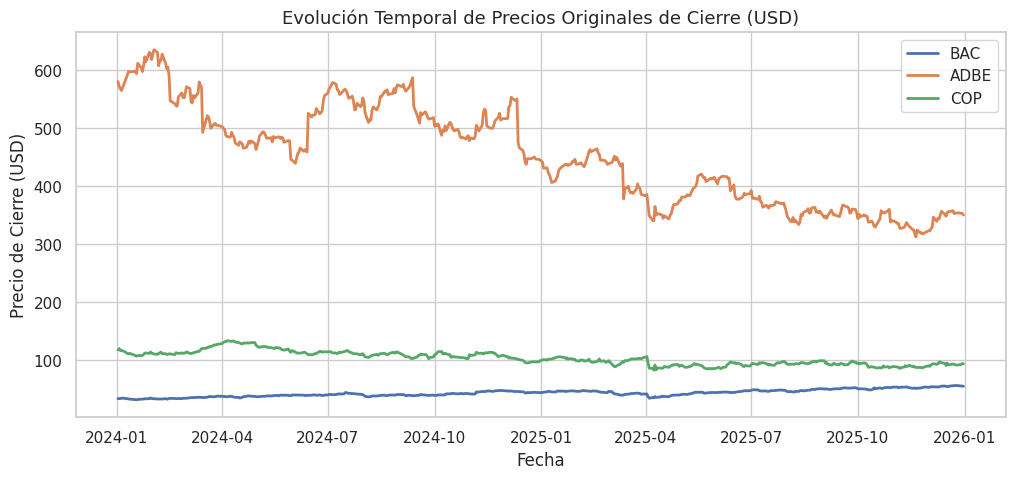

In [8]:
# 2. Graficar en una sola figura la evolución temporal de los precios originales
plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(precios.index, precios[ticker], label=ticker, linewidth=2)

plt.title('Evolución Temporal de Precios Originales de Cierre (USD)', fontsize=13)
plt.xlabel('Fecha')
plt.ylabel('Precio de Cierre (USD)')
plt.legend()
plt.show()

**Prengunta de Interpretacion.**




**3. Grafica Evolucion Temporal Normalizada Base 100.**

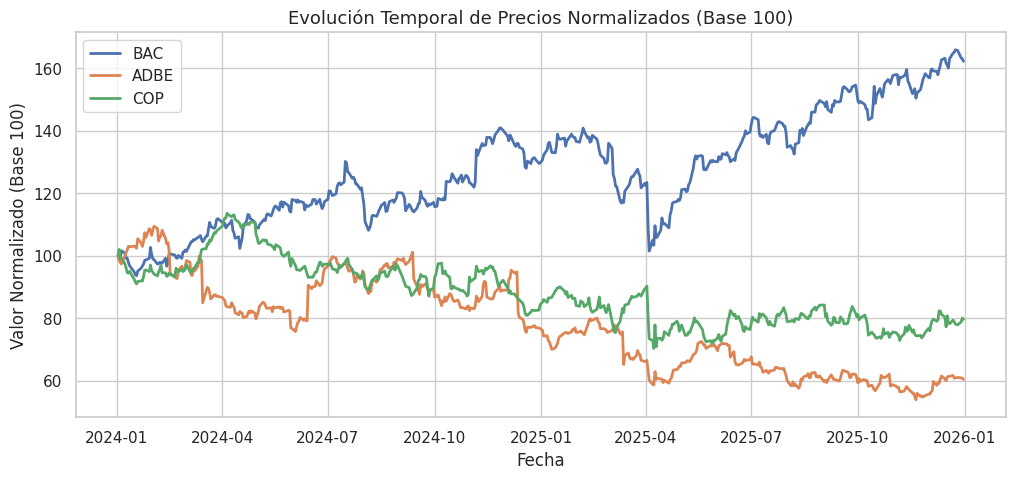

In [9]:
# 3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente
precios_base_100 = (precios / precios.iloc[0]) * 100

plt.figure(figsize=(12, 5))
for ticker in tickers:
    plt.plot(precios_base_100.index, precios_base_100[ticker], label=ticker, linewidth=2)

plt.title('Evolución Temporal de Precios Normalizados (Base 100)', fontsize=13)
plt.xlabel('Fecha')
plt.ylabel('Valor Normalizado (Base 100)')
plt.legend()
plt.show()

**Pregunta de Interpretacion # 1.**

Porque con la normalizacion base 100 iguala el punto de partida, permitiendo evaluar de forma justa el rendimiento porcentual de cada activo a lo largo del tiempo.

La diferencia observada en cada grafico de precio originales nos muestra que el activo ADBE tiene mayor dinamismo, y los demas activos estan en la parte inferior. Pero el grafico de la normalizada 100 nos muestra que el activo BAC tuvo un mayor desempeño.



## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

**1. Calcular Rendimientos y Eliminar Valores Nulos**

In [11]:
# 1. Calcular los rendimientos diarios de los activos y eliminar los valores nulos (NaN)
rendimientos = precios.pct_change().dropna()

print("Primeras filas de los rendimientos diarios calculados:")
display(rendimientos.head())

Primeras filas de los rendimientos diarios calculados:


Ticker,ADBE,BAC,COP
Date,,,
2024-01-03,-0.014274,-0.010915,0.019900
2024-01-04,-0.008290,0.008053,-0.028767
2024-01-05,-0.004321,0.018639,0.000429
2024-01-08,0.028250,-0.007842,-0.017420
2024-01-09,0.009732,-0.015515,-0.015196


**2. Histograma con el Activo mas Volatil.**

El activo más volátil del portafolio es: ADBE (Volatilidad anualizada: 0.3372)


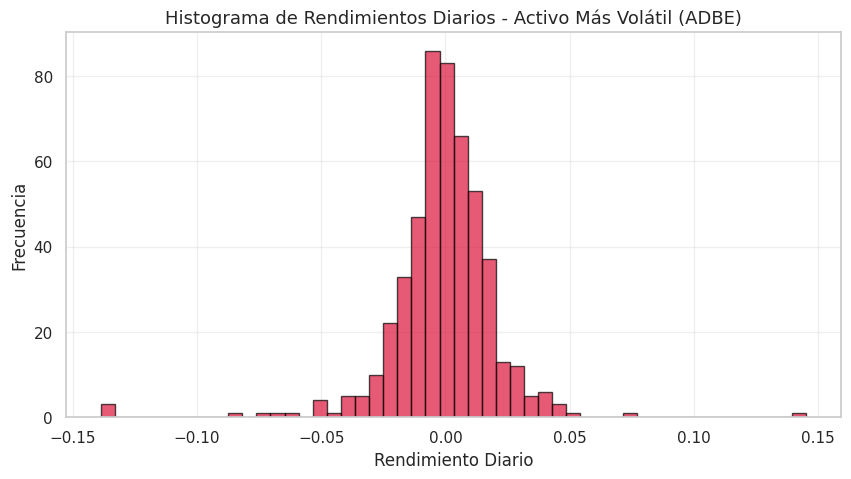

In [12]:
# 2. Genera un histograma para el activo que consideres que haya sido el más volátil
# Identificamos automáticamente cuál activo tiene mayor volatilidad (desviación estándar)
volatilidad_activos = rendimientos.std() * (252 ** 0.5)
activo_mas_volatil = volatilidad_activos.idxmax()

print(f"El activo más volátil del portafolio es: {activo_mas_volatil} (Volatilidad anualizada: {volatilidad_activos[activo_mas_volatil]:.4f})")

plt.figure(figsize=(10, 5))
plt.hist(rendimientos[activo_mas_volatil], bins=50, color='crimson', alpha=0.7, edgecolor='black')
plt.title(f'Histograma de Rendimientos Diarios - Activo Más Volátil ({activo_mas_volatil})', fontsize=13)
plt.xlabel('Rendimiento Diario')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)
plt.show()

**3. Boplot Comparativo de Rendimiento.**

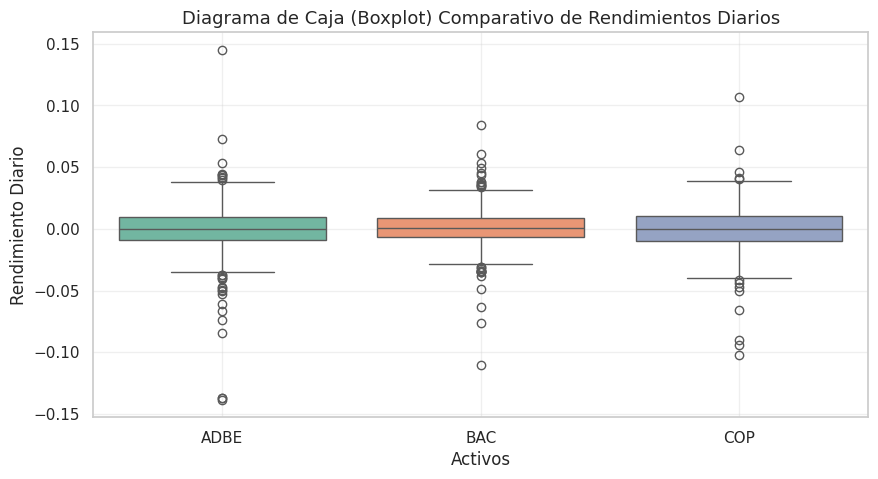

In [13]:
# 3. Diseña un Boxplot comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente
plt.figure(figsize=(10, 5))
sns.boxplot(data=rendimientos, palette="Set2")
plt.title('Diagrama de Caja (Boxplot) Comparativo de Rendimientos Diarios', fontsize=13)
plt.xlabel('Activos')
plt.ylabel('Rendimiento Diario')
plt.grid(True, alpha=0.3)
plt.show()

**Pregunta de Interpretacion # 2.**

**Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?**

El activo que presenta la mayor dispersión es ADBE, cuya caja y rango entre bigotes cubren un espacio vertical más amplio en comparación con BAC y COP. Esto nos indica que ADBE posee un mayor nivel de riesgo de mercado, ya que sus rendimientos diarios experimentan fluctuaciones y desviaciones más intensas con respecto a su media, reflejando mayor incertidumbre y sensibilidad a los cambios del mercado en el corto plazo.

**¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?**

Sí, se identifican claramente numerosos puntos aislados tanto por encima como por debajo de los bigotes en los tres activos (especialmente visibles en los extremos de ADBE y BAC). En el contexto económico reciente, estos outliers representan shocks o movimientos diarios extremos y poco frecuentes (jornadas de ganancias o pérdidas anómalas). Estos comportamientos suelen ser desencadenados por eventos de alto impacto, tales como la publicación de reportes de resultados trimestrales (earnings) que sorprendieron al mercado, anuncios de política monetaria de la Reserva Federal (cambios en tasas de interés) o correcciones sectoriales abruptas (por ejemplo, en el sector tecnológico o financiero).   

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

**1. Calcular Matriz de Correlacion.**

In [14]:
# 1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos
matriz_corr = rendimientos.corr(method='pearson')

print("Matriz de Correlación de Pearson:")
display(matriz_corr)

Matriz de Correlación de Pearson:


Ticker,ADBE,BAC,COP
Ticker,,,
ADBE,1.000000,0.240544,0.166434
BAC,0.240544,1.000000,0.404804
COP,0.166434,0.404804,1.000000


**2. Dibujar el Heatmap utilizando Seaborn.**

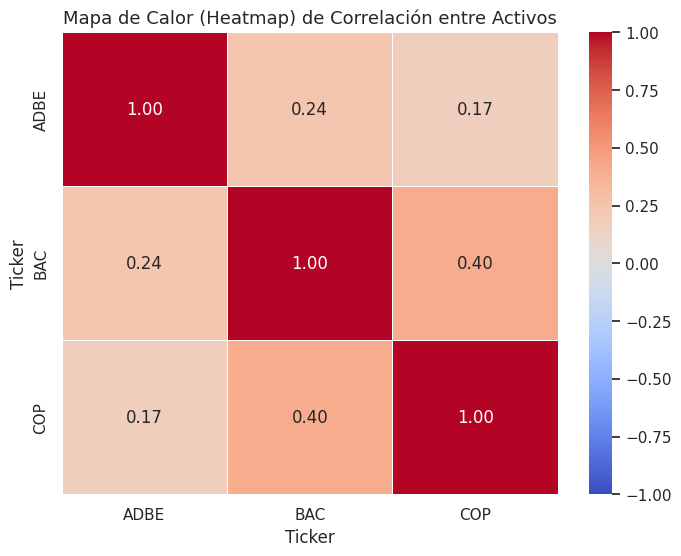

In [15]:
# 2. Grafica un mapa de calor (Heatmap)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=.5)
plt.title('Mapa de Calor (Heatmap) de Correlación entre Activos', fontsize=13)
plt.show()

**Pregunta Interpretacion # 3.**

**¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?**

No, no existe ninguna correlación fuerte. Todas las correlaciones cruzadas son bajas y positivas: ADBE y COP muestran la correlación más débil con un valor de 0.17, ADBE y BAC registran 0.24, y la relación más alta del grupo se da entre BAC y COP con un valor moderado de 0.40. Esto demuestra que los activos se mueven con relativa independencia unos de otros.

**Si tuvieras que armar un portafolio de inversión buscando la diversificación (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?**

Para lograr la máxima diversificación y mitigar el riesgo conjunto del portafolio, elegiría el par formado por ADBE y COP (o en su defecto, la combinación de ADBE con BAC), ya que poseen el coeficiente de correlación más bajo (0.17). Al tener una correlación tan cercana a cero, el comportamiento desacoplado de estos sectores (tecnológico y energético) permite que las caídas de uno puedan ser compensadas o amortiguadas por la estabilidad del otro, reduciendo la volatilidad global de la cartera.

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

In [16]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)

In [17]:
# 1. Generar un DataFrame de resumen estadístico que incluya: Media, Mediana, Desviación Estándar, Mínimo y Máximo
resumen_estadistico = pd.DataFrame({
    'Media (Rend. Diario)': rendimientos.mean(),
    'Mediana (Rend. Diario)': rendimientos.median(),
    'Desviación Estándar (Riesgo)': rendimientos.std(),
    'Mínimo (Peor Día)': rendimientos.min(),
    'Máximo (Mejor Día)': rendimientos.max()
})

print("Resumen de Estadísticas Descriptivas de los Rendimientos Diarios:")
display(resumen_estadistico)

Resumen de Estadísticas Descriptivas de los Rendimientos Diarios:


,Media (Rend. Diario),Mediana (Rend. Diario),Desviación Estándar (Riesgo),Mínimo (Peor Día),Máximo (Mejor Día)
Ticker,,,,,
ADBE,-0.000778,-0.000325,0.021241,-0.138532,0.145115
BAC,0.001089,0.000946,0.015635,-0.110633,0.084288
COP,-0.000290,-0.000356,0.018109,-0.102262,0.107065


**Conclusion**.

A partir del análisis exploratorio cuantitativo realizado sobre los activos BAC, ADBE y COP, presentamos las conclusiones clave y las recomendaciones estratégicas para la conformación de su portafolio:

BAC: Fue el activo con mejor desempeño y mayor consistencia. Presentó un rendimiento medio diario positivo de +0.1089% y la menor volatilidad del grupo (desviación estándar diaria de 1.56%). Esto se tradujo en un crecimiento acumulado superior al +60% en el periodo analizado.

COP: Tuvo un comportamiento moderado con un rendimiento medio de -0.0290% diario y una volatilidad intermedia de 1.81%.

ADBE: Registró el peor desempeño y el mayor riesgo de mercado, con una media diaria de -0.0778% y la desviación estándar más alta del grupo (2.12% diaria). Además, sufrió la peor caída en un solo día (-13.85%), lo que evidencia una alta sensibilidad a shocks sectoriales.

**Beneficios de la Diversificación:**

El mapa de calor de Pearson reveló que la correlación entre los tres activos es baja (entre 0.17 y 0.40). La menor correlación del portafolio se da entre ADBE (Tecnología) y COP (Energía) con tan solo 0.17. Esto confirma que combinar empresas de sectores independientes permite mitigar el riesgo no sistemático, reduciendo las fluctuaciones globales de la cartera sin sacrificar liquidez.

**Recomendación Estratégica:**

Para un perfil de inversión moderado, se recomienda estructurar un portafolio mayoritariamente ponderado en BAC (por su sólida relación rendimiento-riesgo), complementado de forma minoritaria con COP y ADBE para aprovechar el desacoplamiento de sectores y capturar posibles rebotes en la valoración de tecnología y energía.